

# Prueba parcial



## Pipeline del proyecto

El modelo estima `charges` con age, sex, bmi, children, smoker y region. Los datos salen de `pruebaparcial.csv`.

1. Cargar `pruebaparcial.csv`
2. Análisis exploratorio
3. Tratamiento de datos (vacíos y tipos)
4. Detección de valores atípicos
5. Partición train / test
6. Transformación (rellenar, pasar el texto a números, estandarizar)
7. Selección de atributos
8. Validación cruzada
9. Entrenamiento
10. Evaluación en test
11. Predicción de casos nuevos

La escala y la selección se aprenden solo con el train. El test entra al final, ya con el modelo armado.

### Librerías

Antes de tocar los datos dejo cargado lo que voy a usar.

- `pandas` arma la tabla y `numpy` hace las cuentas (ordenar, máscaras).
- `sqrt` saca la raíz del error cuadrático. `pprint` imprime el diccionario de la validación cruzada de forma legible.
- `matplotlib` es para las gráficas. `scipy.stats` lo uso en los percentiles del diagrama de caja.
- `metrics` trae MAE, MSE y R2.

Las que arman el modelo, y que no son un `import` cualquiera:

- `SimpleImputer` rellena vacíos.
- `StandardScaler` estandariza columnas numéricas.
- `OneHotEncoder` pasa el texto a columnas de 0 y 1.
- `ColumnTransformer` aplica un tratamiento distinto según el grupo de columnas.
- `Pipeline` encadena esos pasos para que se ajusten juntos.
- `f_regression` y `SelectKBest` miden qué columnas sirven y se quedan con las mejores.
- `train_test_split`, `KFold` y `cross_validate` parten los datos y validan.
- `make_scorer` mete RMSE y MAPE dentro de esa validación.
- `LinearRegression` es la recta (en varias variables) que estima `charges`.

In [1]:
import numpy as np  # cuentas y para ordenar
from math import sqrt  # la raiz, la uso en el RMSE
from pprint import pprint  # el diccionario de la validacion se ve mas claro

import matplotlib.pyplot as plt  # graficas
import pandas as pd  # la tabla
from scipy import stats  # percentiles del boxplot

from sklearn import metrics  # MAE, MSE, R2
from sklearn.compose import ColumnTransformer  # un trato distinto si la columna es numero o texto
from sklearn.feature_selection import SelectKBest, f_regression  # medir columnas y quedarme con las mejores
from sklearn.impute import SimpleImputer  # por si hay un vacio
from sklearn.linear_model import LinearRegression  # la recta
from sklearn.metrics import make_scorer  # pa meter RMSE y MAPE en la validacion
from sklearn.model_selection import KFold, cross_validate, train_test_split  # cortar y validar
from sklearn.pipeline import Pipeline  # encadena los pasos
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # texto a 0/1, y escalar los numeros

## 1. Carga de datos

El archivo es `pruebaparcial.csv`: age, sex, bmi, children, smoker, region y charges.

`pd.read_csv` lee el archivo y lo deja en un DataFrame. `shape` devuelve `(filas, columnas)`. `head()` muestra las primeras filas para comprobar que las columnas llegaron bien y que `charges` es el gasto.

In [2]:
df = pd.read_csv("pruebaparcial.csv")  # leo el archivo
print(df.shape)  # filas y columnas
df.head()  # las primeras, a ver si cargo bien

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Análisis exploratorio

Antes de modelar miro de qué tipo es cada columna, si falta algún dato y cómo se reparte el gasto.

- `dtypes` dice el tipo de cada columna. age, bmi, children y charges son números. sex, smoker y region son texto.
- `isna()` marca la celda vacía y `sum()` las cuenta por columna.
- `describe()` resume las numéricas: cantidad, media, desviación, mínimo, cuartiles (25%, 50%, 75%) y máximo.

In [3]:
print(df.dtypes)  # de que tipo es cada columna
print()  # salto
print(df.isna().sum())  # vacios por columna
print()
df.describe()  # media, min, max y los cuartiles

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64



,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


`value_counts()` cuenta cuántas filas hay en cada categoría. Sirve para ver si una clase está muy desbalanceada, como smoker (hay muchos más que no fuman).

`corr()` calcula la correlación de Pearson, entre -1 y 1. Cerca de 1, las dos columnas suben juntas. Solo se la pido a las numéricas, porque sex, smoker y region todavía son texto y no entran en esa cuenta.

In [4]:
print(df["sex"].value_counts())  # cuantos de cada sexo
print()
print(df["smoker"].value_counts())  # cuantos fuman
print()
print(df["region"].value_counts())  # cuantos por region
print()
print(df[["age", "bmi", "children", "charges"]].corr())  # correlacion, solo las numericas

sex
male      676
female    662
Name: count, dtype: int64

smoker
no     1064
yes     274
Name: count, dtype: int64

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

               age       bmi  children   charges
age       1.000000  0.109272  0.042469  0.299008
bmi       0.109272  1.000000  0.012759  0.198341
children  0.042469  0.012759  1.000000  0.067998
charges   0.299008  0.198341  0.067998  1.000000


`subplots(1, 2)` abre una figura con dos gráficas.

`boxplot(column="charges", by="smoker")` hace una caja del gasto para los que fuman y otra para los que no. La caja va del cuartil 25 al 75. Los puntos sueltos son los que se salen de los bigotes.

En la segunda gráfica, `scatter` pinta un punto por persona: edad en X y gasto en Y. El `for` separa smoker `yes` y `no` para pintarlos de distinto color. `legend` pone la guía de colores.

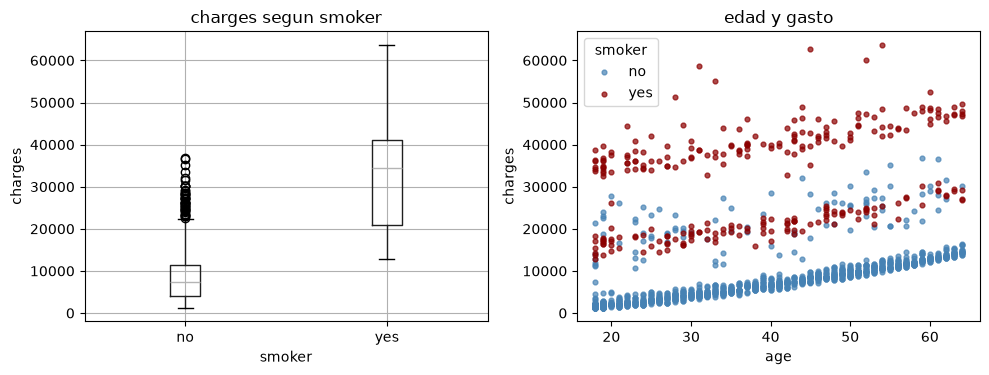

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))  # dos graficas al lado

df.boxplot(column="charges", by="smoker", ax=ax[0])  # caja del gasto, fuma o no
ax[0].set_title("charges segun smoker")  # titulo
ax[0].set_xlabel("smoker")  # eje x
ax[0].set_ylabel("charges")  # eje y
plt.suptitle("")  # el boxplot pone un titulo de mas, lo borro

for valor, color in [("no", "steelblue"), ("yes", "darkred")]:  # azul no fuma, rojo si
    parte = df[df["smoker"] == valor]  # solo ese grupo
    ax[1].scatter(parte["age"], parte["charges"], s=12, c=color, label=valor, alpha=0.7)  # un punto por persona

ax[1].set_xlabel("age")
ax[1].set_ylabel("charges")
ax[1].set_title("edad y gasto")
ax[1].legend(title="smoker")  # que color es cual
plt.tight_layout()  # que no se pisen los titulos
plt.show()  # la muestro

## 3. Tratamiento de datos

`charges` es lo que quiero predecir, así que no puede quedar dentro de las variables.

`drop(columns="charges")` lo saca de X. `y` se queda con esa columna sola. `columns.tolist()` imprime los nombres que sí entran al modelo.

`isna().sum().sum()` suma los vacíos de toda la tabla. En este archivo da 0. Más adelante igual dejo un imputer: si una fila nueva llega con un hueco, el pipeline lo rellena en vez de romperse. sex, smoker y region siguen en texto hasta la transformación.

In [6]:
X = df.drop(columns="charges")  # el gasto no puede ir como variable
y = df["charges"]  # esto es lo que voy a predecir
print(X.columns.tolist())  # las que si entran
print("filas", len(df), "| vacios", int(df.isna().sum().sum()))  # cuantas filas y si falta algo

['age', 'sex', 'bmi', 'children', 'smoker', 'region']
filas 1338 | vacios 0


## 4. Detección de valores atípicos

Uso la regla del diagrama de caja. `limites_bp` es una función mía: le paso una columna y me devuelve el límite de abajo y el de arriba.

- `stats.scoreatpercentile(variable, 25)` es Q1, el valor que deja el 25% de los datos por debajo.
- El percentil 75 es Q3.
- `RIC = Q3 - Q1` es el alto de la caja (rango intercuartílico).
- El bigote inferior es `Q1 - 1.5 * RIC` y el superior `Q3 + 1.5 * RIC`.

Lo que cae fuera de esos dos números lo cuento como atípico. Después, en `charges`, miro cuántos de esos altos son fumadores. Si casi todos fuman, no es un error de tipeo: es el gasto real de ese grupo.

In [7]:
def limites_bp(variable):  # le paso una columna y me da los dos limites
    Q1 = stats.scoreatpercentile(variable, 25)  # primer cuartil, el 25%
    Q3 = stats.scoreatpercentile(variable, 75)  # tercer cuartil
    RIC = Q3 - Q1  # alto de la caja
    li = Q1 - 1.5 * RIC  # de aqui para abajo es raro
    ls = Q3 + 1.5 * RIC  # de aqui para arriba tambien
    return li, ls  # los devuelvo

for col in ["age", "bmi", "children", "charges"]:  # una por una
    li, ls = limites_bp(df[col])  # limites de esa columna
    fuera = (df[col] < li) | (df[col] > ls)  # los que se salen
    print(col, "fuera:", int(fuera.sum()), " limites", round(li, 2), round(ls, 2))  # cuantos y entre que valores

li, ls = limites_bp(df["charges"])  # lo repito solo con el gasto
altos = df[df["charges"] > ls]  # los caros
print()
print("charges por encima del limite:", len(altos))  # cuantos se pasan
print("de esos, fumadores:", int((altos["smoker"] == "yes").sum()))  # a ver si fuman o es basura

age fuera: 0  limites -9.0 87.0
bmi fuera: 9  limites 13.7 47.29
children fuera: 0  limites -3.0 5.0
charges fuera: 139  limites -13109.15 34489.35

charges por encima del limite: 139
de esos, fumadores: 136


`boxplot` dibuja esa misma caja. En bmi se ven pocos puntos fuera. En charges la cola de arriba es larga: ahí están los gastos caros.

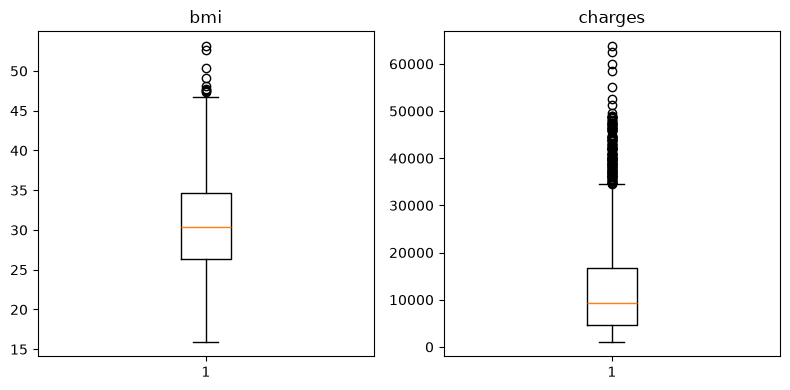

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))  # otra vez dos graficas
ax[0].boxplot(df["bmi"])  # caja del bmi
ax[0].set_title("bmi")  # titulo
ax[1].boxplot(df["charges"])  # caja del gasto, aca se ve la cola
ax[1].set_title("charges")  # titulo
plt.tight_layout()  # acomodo
plt.show()  # muestro

Los gastos altos no son un error de carga: casi todos son personas que fuman. Si los borro, el modelo no aprende justo los casos caros. Los dejo.

## 5. Partición

`train_test_split` mezcla las filas y las corta en dos.

- `test_size=0.2` deja el 20% para probar al final y el 80% para entrenar.
- `random_state=42` fija la mezcla. Si vuelvo a correr la celda, salen las mismas filas.
- Devuelve cuatro pedazos: `X_train`, `X_test`, `y_train`, `y_test`.

El test no se usa para calcular medias, ni para elegir columnas, ni para ajustar la recta. Si no, el error saldría más bonito de lo que es.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(  # cuatro pedazos
    X, y, test_size=0.2, random_state=42  # 20% para probar, 42 para que el corte no cambie
)
print("train", X_train.shape, "test", X_test.shape)  # cuantas filas quedaron en cada uno

train (1070, 6) test (268, 6)


## 6. Transformación de variables

Hay dos tipos de columna y cada uno lleva un camino. `Pipeline` los junta en orden: al hacer `fit`, corre el primer paso y con eso alimenta el segundo.

Camino numérico (`age`, `bmi`, `children`):

- `SimpleImputer(strategy="mean")` cambia un vacío por la media de esa columna, calculada en el train.
- `StandardScaler` resta esa media y divide por la desviación. La columna queda con media 0 y desviación 1. Así la edad (años) y el bmi no pesan distinto solo porque uno maneja números más grandes.

Camino de texto (`sex`, `smoker`, `region`):

- `SimpleImputer(strategy="most_frequent")` rellena con la moda, que es lo que toca en texto.
- `OneHotEncoder` crea una columna de 0 y 1 por categoría. `drop="first"` quita una de cada grupo: si no, `smoker_yes` y `smoker_no` dirían lo mismo y la regresión se confunde. `sparse_output=False` devuelve una matriz normal.

`ColumnTransformer` aplica `numeros` solo a las tres columnas numéricas y `texto` a las tres de categorías. El resto no se toca porque no queda ninguna fuera.

`fit_transform` ajusta todo con el train y devuelve la matriz ya lista. `get_feature_names_out()` pone el nombre de cada columna nueva, por ejemplo `num__age` o `cat__smoker_yes`.

In [10]:
columnas_num = ["age", "bmi", "children"]  # estas son numeros
columnas_cat = ["sex", "smoker", "region"]  # estas son texto

numeros = Pipeline([
    ("rellenar", SimpleImputer(strategy="mean")),  # si falta algo, pongo la media
    ("escalar", StandardScaler()),  # media 0 y desviacion 1
])

texto = Pipeline([
    ("rellenar", SimpleImputer(strategy="most_frequent")),  # en texto, el vacio se llena con la moda
    ("a_numeros", OneHotEncoder(drop="first", sparse_output=False)),  # paso a 0 y 1, sin repetir columna
])

prepro = ColumnTransformer([
    ("num", numeros, columnas_num),  # este camino solo a age, bmi y children
    ("cat", texto, columnas_cat),  # este a sex, smoker y region
])

X_train_t = prepro.fit_transform(X_train)  # aprende la escala con el train y ya transforma
print(prepro.get_feature_names_out())  # como quedaron llamadas las columnas
print("forma", X_train_t.shape)  # filas y columnas ya cambiadas

['num__age' 'num__bmi' 'num__children' 'cat__sex_male' 'cat__smoker_yes'
 'cat__region_northwest' 'cat__region_southeast' 'cat__region_southwest']
forma (1070, 8)


## 7. Selección de atributos

`f_regression` calcula el estadístico F de cada columna contra `charges`. Mientras más alto, más se mueve esa columna junto con el gasto. También devuelve el p-valor; lo dejo en `_` porque aquí no lo uso.

`np.argsort` da las posiciones de menor a mayor. `[::-1]` las voltea para imprimir primero la más relacionada.

`SelectKBest(score_func=f_regression, k=4)` se queda con las 4 de F más alto. En este train son smoker, age, bmi y children. Sexo y región quedan muy abajo, así que salen.

El `Pipeline` del modelo tiene tres pasos, y el orden importa:

1. `preparar`: el ColumnTransformer de arriba.
2. `elegir`: el SelectKBest.
3. `regresion`: `LinearRegression(fit_intercept=True)`, la recta con término independiente.

Cuando más adelante llame a `fit`, los tres se ajustan con los mismos datos y en ese orden. No hace falta transformar el test a mano.

In [11]:
nombres = prepro.get_feature_names_out()  # los nombres, para imprimirlos al lado del F
f_vals, _ = f_regression(X_train_t, y_train)  # F de cada columna. el _ es el p-valor y no lo uso

print("F de cada variable")
for i in np.argsort(f_vals)[::-1]:  # de la que mas pega con charges a la que menos
    print(f"{nombres[i]:28s} {f_vals[i]:8.1f}")  # nombre y su F

k = 4  # con 4 basta, sex y region quedan muy abajo
modelo = Pipeline([
    ("preparar", prepro),  # primero transforma
    ("elegir", SelectKBest(score_func=f_regression, k=k)),  # se queda con las 4
    ("regresion", LinearRegression(fit_intercept=True)),  # la recta, con intercepto
])
print()
print(modelo)  # los pasos, para no perderme

F de cada variable
cat__smoker_yes                1660.0
num__age                         92.1
num__bmi                         43.3
num__children                     5.5
cat__region_southeast             4.9
cat__sex_male                     3.5
cat__region_southwest             1.3
cat__region_northwest             1.2

Pipeline(steps=[('preparar',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('rellenar',
                                                                   SimpleImputer()),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  Pipeline(steps=[('rellenar',
                                             

## 8. Validación cruzada

No quiero fiarme de un solo corte. `KFold(n_splits=5, shuffle=True)` parte el train en 5 trozos, barajados. En cada vuelta entrena con 4 y mide con el que sobró.

`cross_validate` repite eso y, en cada vuelta, vuelve a ajustar el pipeline entero (escala, selección y recta). El trozo que se mide no participa en el ajuste.

`make_scorer` envuelve una función mía para que entre en `scoring`. `greater_is_better=False` le dice a sklearn que un error más chico es mejor, y por eso MAE, RMSE y MAPE los guarda en negativo. R2 no, porque ahí más alto es mejor.

- MAE: error absoluto medio.
- RMSE: raíz del error cuadrático. Uso `sqrt` porque en esta versión de sklearn `mean_squared_error` ya no tiene el argumento `squared`.
- MAPE: error en porcentaje, `|(real - predicho) / real|` promediado y por 100.
- R2: qué tanto de la variación de `charges` explica el modelo. 1 sería un ajuste perfecto.

Al imprimir las medias les quito el signo con un menos, para leer el error en positivo.

In [ ]:
metricas = {  # como voy a medir en cada vuelta
    "MAE": "neg_mean_absolute_error",  # error absoluto. sklearn lo guarda negativo
    "RMSE": make_scorer(
        lambda y, y_pred: sqrt(metrics.mean_squared_error(y, y_pred)),  # raiz del error al cuadrado
        greater_is_better=False,  # mientras mas chico, mejor
    ),
    "MAPE": make_scorer(
        lambda y, y_pred: np.mean(np.abs((y - y_pred) / y)) * 100,  # el error en porcentaje
        greater_is_better=False,
    ),
    "R2": "r2",  # este al reves: mas alto es mejor
}

cv = cross_validate(  # entrena y prueba 5 veces, el modelo se rearma en cada una
    modelo,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),  # 5 partes, mezcladas
    scoring=metricas,
)
pprint(cv)  # como le fue en cada parte
print()
print("MAE medio :", round(-cv["test_MAE"].mean(), 2))  # le saco el menos
print("RMSE medio:", round(-cv["test_RMSE"].mean(), 2))  # igual
print("MAPE medio:", round(-cv["test_MAPE"].mean(), 2))  # el porcentaje promedio
print("R2 medio  :", round(cv["test_R2"].mean(), 4))  # este ya venia bien

{'fit_time': array([0.00900602, 0.00846887, 0.00872397, 0.00715113, 0.00718594]),
 'score_time': array([0.00474501, 0.00522304, 0.0047543 , 0.00393081, 0.00444388]),
 'test_MAE': array([-4473.40482652, -4440.25787585, -3929.72277735, -4224.47498533,
       -4056.73727191]),
 'test_MAPE': array([-39.60193789, -42.07671752, -48.74526969, -40.94615918,
       -42.09934681]),
 'test_R2': array([0.72637091, 0.71325094, 0.77245945, 0.70948635, 0.7734697 ]),
 'test_RMSE': array([-6607.25812141, -6452.16825682, -5464.29666011, -6424.66119868,
       -5667.06838685])}

MAE medio : 4224.92
RMSE medio: 6123.09
MAPE medio: 42.69
R2 medio  : 0.739


## 9. Entrenamiento

`fit` ajusta los tres pasos con todo el train, no solo con 4 de las 5 partes.

`named_steps` entra a un paso por el nombre que le puse en el pipeline.

- `get_feature_names_out()` recupera los nombres después de transformar.
- `get_support()` es una máscara de True y False: True en las columnas que `SelectKBest` conservó.
- `coef_` son los pesos de esas columnas. `intercept_` es el término independiente.

Age, bmi y children quedaron estandarizados, así que su coeficiente es el cambio en `charges` cuando esa columna sube una desviación estándar, no cuando sube un año o un punto de bmi. `smoker_yes` sigue siendo 0 o 1: el coeficiente es lo que se suma al gasto si la persona fuma.

In [13]:
modelo.fit(X_train, y_train)  # ahora si, con todo el train

nombres = modelo.named_steps["preparar"].get_feature_names_out()  # nombres ya transformados
quedan = modelo.named_steps["elegir"].get_support()  # True en las que SelectKBest dejo
coefs = modelo.named_steps["regresion"].coef_  # cuanto pesa cada una

print("se quedan:")
for nombre, coef in zip(nombres[quedan], coefs):  # solo las 4
    print(f"  {nombre:28s} {coef:10.2f}")  # nombre y su peso
print("termino independiente:", round(modelo.named_steps["regresion"].intercept_, 2))  # donde arranca la recta

se quedan:
  num__age                        3616.32
  num__bmi                        1978.42
  num__children                    519.23
  cat__smoker_yes                23653.21
termino independiente: 8482.81


## 10. Evaluación

`predict` pasa el test por los mismos tres pasos (con la escala y las columnas ya aprendidas en el train) y devuelve el gasto estimado.

- `mean_absolute_error`: media de `|real - predicho|`, en las mismas unidades que `charges`.
- `mean_squared_error`: media del error al cuadrado. Un error grande pesa más.
- `sqrt(MSE)` es el RMSE, otra vez en unidades de gasto.
- El MAPE de esta celda está en porcentaje, igual que el de la validación: media de `|real - predicho| / real`, por 100.
- `r2_score`: 1 explica todo, 0 no mejora a predecir siempre la media.

In [14]:
y_pred = modelo.predict(X_test)  # que gasto le pone a cada uno del test

MAE = metrics.mean_absolute_error(y_test, y_pred)  # se equivoca, en promedio, esto
MSE = metrics.mean_squared_error(y_test, y_pred)  # lo mismo pero al cuadrado
RMSE = sqrt(MSE)  # otra vez en dolares, mas o menos
MAPE = np.mean(np.abs((y_test - y_pred) / y_test)) * 100  # en porcentaje, como en la validacion
R2 = metrics.r2_score(y_test, y_pred)  # 1 seria perfecto

print("MAE : %.4f" % MAE)  # error medio
print("MSE : %.4f" % MSE)  # al cuadrado
print("RMSE: %.4f" % RMSE)  # la raiz
print("MAPE: %.4f" % MAPE)  # el porcentaje
print("R2  : %.4f" % R2)  # que tanto explica

MAE : 4213.7986
MSE : 33981653.9502
RMSE: 5829.3785
MAPE: 48.0500
R2  : 0.7811


`scatter` pone el gasto real en el eje X y la predicción en el eje Y. Cada punto es una persona del test.

`plot` dibuja la línea donde predicción = valor real, de la esquina del mínimo a la del máximo. Si el punto cae encima, el modelo acertó. Si queda arriba, se pasó; si queda abajo, se quedó corto.

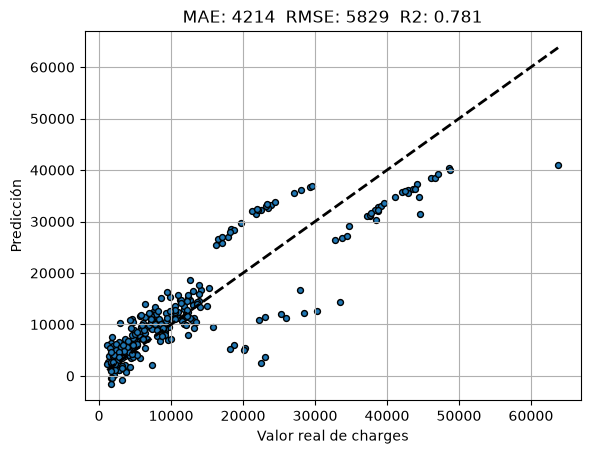

In [15]:
fig, ax = plt.subplots()  # un solo grafico
ax.scatter(y_test, y_pred, edgecolors=(0, 0, 0), s=18)  # real contra lo que predijo
ax.plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw=2)  # si cae en la linea, le atino
ax.set_xlabel("Valor real de charges")  # eje x, el gasto de verdad
ax.set_ylabel("Predicción")  # eje y, lo que dijo el modelo
plt.title("MAE: %.0f  RMSE: %.0f  R2: %.3f" % (MAE, RMSE, R2))  # dejo el error en el titulo
plt.grid()  # cuadricula
plt.show()

## 11. Predicción de observaciones nuevas

Armo un DataFrame con las mismas columnas que X. No hace falta estandarizarlo ni pasarlo a 0 y 1 a mano: `predict` recorre el pipeline y aplica lo que ya aprendió con el train.

Las dos filas son la misma persona. Solo cambia `smoker`, para ver cuánto mueve el gasto esa columna sola. `charges_estimado` es la salida del modelo, no un dato del csv.

In [16]:
nuevos = pd.DataFrame([  # dos personas inventadas, mismas columnas que X
    {"age": 40, "sex": "male", "bmi": 30.0, "children": 2, "smoker": "no", "region": "northeast"},  # no fuma
    {"age": 40, "sex": "male", "bmi": 30.0, "children": 2, "smoker": "yes", "region": "northeast"},  # la misma, pero fuma
])

nuevos["charges_estimado"] = modelo.predict(nuevos)  # el pipeline escala solo, no lo hago a mano
nuevos  # la tabla con el gasto que estimo

,age,sex,bmi,children,smoker,region,charges_estimado
0,40,male,30.0,2,no,northeast,8845.850119
1,40,male,30.0,2,yes,northeast,32499.061765
